Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

df = pd.read_csv("FakeNewsNet.csv")

df.head()

,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1


Prepare Text Data

In [2]:
df['title'] = df['title'].fillna('').astype(str)

df['label'] = df['real'].map({
    1: 'Real',
    0: 'Fake'
})

df = df.dropna(subset=['real'])

df[['title', 'label']].head()

,title,label
0,Kandi Burruss Explodes Over Rape Accusation on...,Real
1,People's Choice Awards 2018: The best red carp...,Real
2,Sophia Bush Sends Sweet Birthday Message to 'O...,Real
3,Colombian singer Maluma sparks rumours of inap...,Real
4,Gossip Girl 10 Years Later: How Upper East Sid...,Real


Apply Count Vectorization

In [3]:
vectorizer = CountVectorizer(
    stop_words='english',
    max_features=5000
)

X = vectorizer.fit_transform(df['title'])

feature_names = vectorizer.get_feature_names_out()

print("Vocabulary Size:", len(feature_names))
print("Document-Term Matrix Shape:", X.shape)

Vocabulary Size: 5000
Document-Term Matrix Shape: (23196, 5000)


Analyse Overall Word Frequencies

In [4]:
word_frequency = np.asarray(X.sum(axis=0)).flatten()

word_freq_df = pd.DataFrame({
    'Word': feature_names,
    'Frequency': word_frequency
})

word_freq_df = word_freq_df.sort_values(
    by='Frequency',
    ascending=False
)

display(word_freq_df.head(20))

,Word,Frequency
2495,kardashian,1172
3126,new,1068
2417,jennifer,800
2415,jenner,775
26,2018,766
383,baby,728
2547,kim,722
4860,wedding,679
4303,star,656
3958,season,648


Compare Word Frequencies in Fake and Real News

In [5]:
fake_indices = df['real'].values == 0
real_indices = df['real'].values == 1

fake_word_freq = np.asarray(
    X[fake_indices].sum(axis=0)
).flatten()

real_word_freq = np.asarray(
    X[real_indices].sum(axis=0)
).flatten()

comparison = pd.DataFrame({
    'Word': feature_names,
    'Fake_Frequency': fake_word_freq,
    'Real_Frequency': real_word_freq
})

display(comparison.head(10))

,Word,Fake_Frequency,Real_Frequency
0,000,16,69
1,10,23,161
2,100,8,54
3,10th,2,8
4,11,12,53
5,12,6,58
6,13,8,85
7,14,6,54
8,15,17,82
9,16,5,33


Identify Most Frequent Words in Fake News

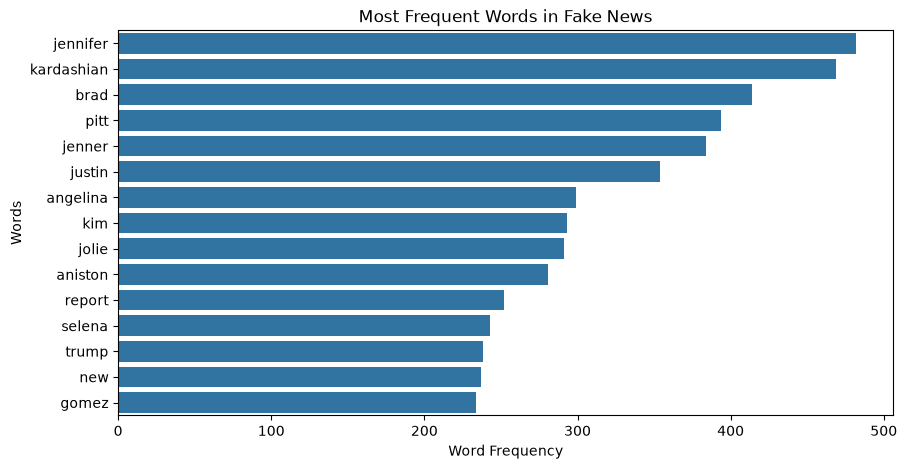

In [6]:
fake_top_words = comparison.sort_values(
    by='Fake_Frequency',
    ascending=False
).head(15)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=fake_top_words,
    x='Fake_Frequency',
    y='Word'
)

plt.title("Most Frequent Words in Fake News")
plt.xlabel("Word Frequency")
plt.ylabel("Words")

plt.show()

Identify Most Frequent Words in Real News

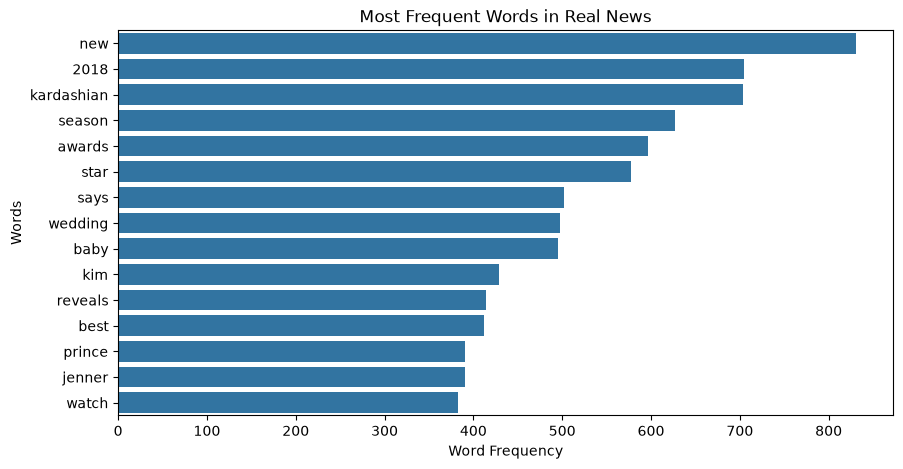

In [7]:
real_top_words = comparison.sort_values(
    by='Real_Frequency',
    ascending=False
).head(15)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=real_top_words,
    x='Real_Frequency',
    y='Word'
)

plt.title("Most Frequent Words in Real News")
plt.xlabel("Word Frequency")
plt.ylabel("Words")

plt.show()

Compare Feature Effectiveness Using Chi-Square

In [8]:
chi_scores, p_values = chi2(X, df['real'])

chi_results = pd.DataFrame({
    'Word': feature_names,
    'Chi_Square_Score': chi_scores,
    'P_Value': p_values
})

chi_results = chi_results.sort_values(
    by='Chi_Square_Score',
    ascending=False
)

display(chi_results.head(20))

,Word,Chi_Square_Score,P_Value
592,brad,978.638505,7.898324e-215
3377,pitt,961.114828,5.089425e-211
252,angelina,647.990939,6.110030e-143
2451,jolie,625.074498,5.889514e-138
256,aniston,619.764327,8.414247e-137
2417,jennifer,538.616004,3.771539e-119
3724,report,526.902605,1.332931e-116
2484,justin,396.473845,3.225096e-88
4066,shelton,347.708625,1.336976e-77
1999,gwen,339.237461,9.352732e-76


visualise imp features

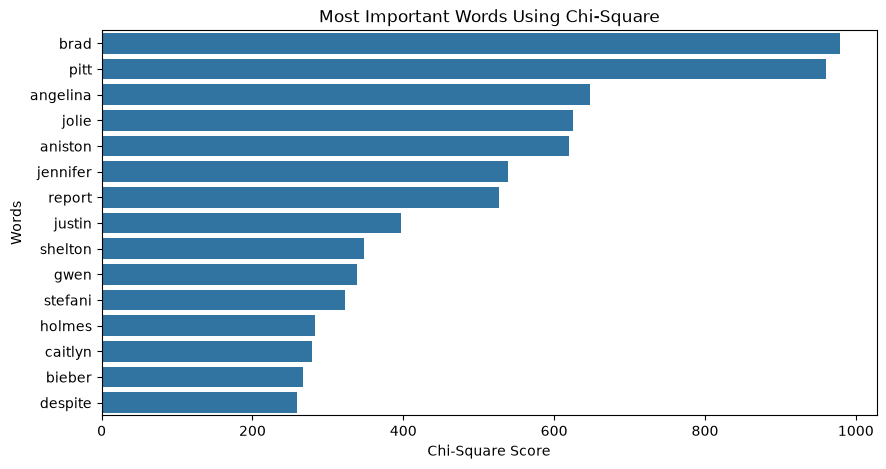

In [9]:
top_features = chi_results.head(15)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_features,
    x='Chi_Square_Score',
    y='Word'
)

plt.title("Most Important Words Using Chi-Square")
plt.xlabel("Chi-Square Score")
plt.ylabel("Words")

plt.show()

final results

In [10]:
print("COUNT VECTORIZATION ANALYSIS")

print("\nTotal Articles:", len(df))

print("Vocabulary Size:", len(feature_names))

print("\nTop 10 Overall Frequent Words:")
display(word_freq_df.head(10))

print("\nTop 10 Fake News Words:")
display(fake_top_words.head(10))

print("\nTop 10 Real News Words:")
display(real_top_words.head(10))

print("\nTop 10 Important Features:")
display(chi_results.head(10))

COUNT VECTORIZATION ANALYSIS

Total Articles: 23196
Vocabulary Size: 5000

Top 10 Overall Frequent Words:


,Word,Frequency
2495,kardashian,1172
3126,new,1068
2417,jennifer,800
2415,jenner,775
26,2018,766
383,baby,728
2547,kim,722
4860,wedding,679
4303,star,656
3958,season,648



Top 10 Fake News Words:


,Word,Fake_Frequency,Real_Frequency
2417,jennifer,482,318
2495,kardashian,469,703
592,brad,414,64
3377,pitt,394,53
2415,jenner,384,391
2484,justin,354,233
252,angelina,299,63
2547,kim,293,429
2451,jolie,291,63
256,aniston,281,56



Top 10 Real News Words:


,Word,Fake_Frequency,Real_Frequency
3126,new,237,831
26,2018,61,705
2495,kardashian,469,703
3958,season,21,627
376,awards,37,597
4303,star,79,577
3926,says,136,502
4860,wedding,181,498
383,baby,233,495
2547,kim,293,429



Top 10 Important Features:


,Word,Chi_Square_Score,P_Value
592,brad,978.638505,7.898324e-215
3377,pitt,961.114828,5.089425e-211
252,angelina,647.990939,6.110030e-143
2451,jolie,625.074498,5.889514e-138
256,aniston,619.764327,8.414247e-137
2417,jennifer,538.616004,3.771539e-119
3724,report,526.902605,1.332931e-116
2484,justin,396.473845,3.225096e-88
4066,shelton,347.708625,1.336976e-77
1999,gwen,339.237461,9.352732e-76
